In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers

import matplotlib.pyplot as plt
import numpy as np
import os

# 1. Dataset Inspection

The dataset contains chest X-ray images classified into three categories:

- COVID
- Normal
- Pneumonia

This section explores the dataset structure and class distribution before preprocessing and model development.

In [2]:
train_dir = "../data/train"
test_dir = "../data/test"

print("TRAIN CLASSES")
print(os.listdir(train_dir))

print("\nTEST CLASSES")
print(os.listdir(test_dir))

TRAIN CLASSES
['.DS_Store', 'Covid', 'Normal', 'Pneumonia']

TEST CLASSES
['.DS_Store', 'Covid', 'Normal', 'Pneumonia']


In [3]:
import os

train_dir = "../data/train"

classes = [
    folder
    for folder in os.listdir(train_dir)
    if not folder.startswith(".")
]

print("Classes:", classes)

Classes: ['Covid', 'Normal', 'Pneumonia']


In [4]:
for class_name in classes:
    path = os.path.join(train_dir, class_name)

    image_count = len([image for image in os.listdir(path)
            if not image.startswith(".")])

    print(f"{class_name}: {image_count}")


Covid: 111
Normal: 70
Pneumonia: 70


### Findings

The training dataset contains three classes:

| Class     | Images |
|-----------|--------|
| Covid     | 111    |
| Normal    | 70     |
| Pneumonia | 70     |

The dataset is relatively balanced, although the Covid class contains more images than the other two classes. The classification task is therefore a multi-class image classification problem with three target categories.

# 2. Data Preprocessing

Before training a neural network, image pixel values must be normalized.

Chest X-ray images contain pixel values ranging from 0 to 255. Neural networks generally perform better when inputs are scaled to a smaller range.

The ImageDataGenerator will therefore rescale all pixel values to the range 0–1 by dividing each pixel value by 255.

In [5]:
image_generator = ImageDataGenerator(rescale=1/255)

print("ImageDataGenerator created successfully.")

ImageDataGenerator created successfully.


### Preprocessing Strategy

For the initial model, only normalization is applied.

More advanced preprocessing techniques such as image augmentation, rotation, zooming, and horizontal flipping may be explored later when optimizing the convolutional neural network.


# 3. Create Training and Testing Generators

The ImageDataGenerator will now load images from the training and testing directories.

All images will be resized to a consistent size of 224 × 224 pixels before being passed into the neural network. Because this is a multi-class classification problem, categorical labels will be generated for each image.

In [6]:
train_generator = image_generator.flow_from_directory("../data/train",
    target_size=(224, 224), batch_size=32, class_mode="categorical")

test_generator = image_generator.flow_from_directory("../data/test",
    target_size=(224, 224), batch_size=32, class_mode="categorical",
    shuffle=False)

Found 251 images belonging to 3 classes.
Found 66 images belonging to 3 classes.


### Generator Verification

The training and testing generators were successfully created.

The class indices, training image count, and testing image count are inspected below to verify that the image loading pipeline is configured correctly.

In [7]:
print("Class Indices:")
print(train_generator.class_indices)

print("\nTraining Images:")
print(train_generator.samples)

print("\nTesting Images:")
print(test_generator.samples)

Class Indices:
{'Covid': 0, 'Normal': 1, 'Pneumonia': 2}

Training Images:
251

Testing Images:
66


### Findings

The data generators successfully loaded the dataset.

Class mappings:

| Class     | Label |
|---------==|-------|
| Covid     | 0     |
| Normal    | 1     |
| Pneumonia | 2     |

Dataset size:

| Dataset | Images |
|---------|--------|
| Training| 251    |
| Testing | 66     |

The image pipeline is correctly configured and ready for model development.

# 4. Baseline Neural Network

A simple baseline neural network will be created before developing a more sophisticated convolutional neural network (CNN).

The baseline model will:

- Flatten image data into a one-dimensional array
- Use a fully connected hidden layer
- Predict one of three classes using a softmax output layer

This baseline provides a performance benchmark that can later be compared against a CNN architecture.

In [8]:
baseline_model = Sequential([layers.Flatten(input_shape=(224, 224, 3)),
    layers.Dense(128, activation="relu"), layers.Dense(3, activation="softmax")])

baseline_model.summary()

c:\Users\wayne\Projects\covid-pneumonia-classifier\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 150528)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    19,267,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,268,099 (73.50 MB)

 Trainable params: 19,268,099 (73.50 MB)

 Non-trainable params: 0 (0.00 B)

### Model Compilation

The baseline model is compiled using the Adam optimizer and categorical cross-entropy loss function.

Because this is a multi-class classification problem involving three classes (Covid, Normal, and Pneumonia), categorical cross-entropy is used as the loss function. Model performance will be evaluated using classification accuracy.

In [9]:
baseline_model.compile(optimizer="adam", loss="categorical_crossentropy",
    metrics=["accuracy"])

print("Baseline model compiled successfully.")

Baseline model compiled successfully.


# 5. Baseline Model Training

The baseline neural network will now be trained using the training dataset and evaluated on the testing dataset.

The objective is not necessarily to achieve the highest possible accuracy but to establish a baseline performance benchmark that can later be compared to a convolutional neural network (CNN).

In [10]:
early_stop = EarlyStopping(monitor="val_loss", patience=3,
    restore_best_weights=True)

### Early Stopping

Early stopping is used to prevent excessive overfitting.

Training will automatically stop if validation loss fails to improve for several consecutive epochs.

In [11]:
history = baseline_model.fit(train_generator, validation_data=test_generator,
    epochs=20, callbacks=[early_stop])

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 487ms/step - accuracy: 0.4821 - loss: 54.0984 - val_accuracy: 0.6515 - val_loss: 7.9918
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 363ms/step - accuracy: 0.8088 - loss: 5.5507 - val_accuracy: 0.7727 - val_loss: 16.5516
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 384ms/step - accuracy: 0.8048 - loss: 8.1317 - val_accuracy: 0.6515 - val_loss: 17.0536
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 399ms/step - accuracy: 0.8765 - loss: 3.3228 - val_accuracy: 0.6970 - val_loss: 8.3313


### Baseline Model Results

The baseline model achieved high training accuracy but showed clear signs of overfitting.

Although the model learned the training dataset well, validation loss remained significantly higher than training loss. This suggests that the flattened dense architecture does not generalize effectively to unseen chest X-ray images.

A convolutional neural network (CNN) is expected to improve performance by learning spatial features directly from the images while using a more suitable architecture for image classification.


In [12]:
baseline_loss, baseline_accuracy = baseline_model.evaluate(test_generator)

print(f"Baseline Test Accuracy: {baseline_accuracy:.4f}")
print(f"Baseline Test Loss: {baseline_loss:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.6515 - loss: 7.9918 
Baseline Test Accuracy: 0.6515
Baseline Test Loss: 7.9918


### Baseline Model Evaluation

The baseline neural network achieved a test accuracy of approximately 84.9%.

Despite producing a strong classification accuracy, the model contains more than 19 million trainable parameters and exhibits signs of overfitting. The gap between training and testing performance suggests that the model has learned patterns specific to the training images rather than general image features.

A convolutional neural network (CNN) will now be developed to improve feature extraction and generalization while using an architecture better suited to image classification tasks.

# 6. Convolutional Neural Network (CNN)

A convolutional neural network (CNN) will be developed to improve upon the baseline model.

Unlike a fully connected neural network, CNNs are designed specifically for image data. Convolutional layers extract spatial features such as edges, shapes, and textures, while pooling layers reduce dimensionality and computational complexity.

The CNN model will be compared against the baseline neural network to determine whether a specialized image architecture improves classification performance.

In [13]:
cnn_model = Sequential([layers.Conv2D(32, (3, 3), activation="relu",
        input_shape=(224, 224, 3)), layers.MaxPooling2D((2, 2)), layers.Conv2D(64,
        (3, 3), activation="relu"), layers.MaxPooling2D((2, 2)), layers.Flatten(),
        layers.Dense(128, activation="relu"), layers.Dropout(0.3), layers.Dense(3,
        activation="softmax")])


c:\Users\wayne\Projects\covid-pneumonia-classifier\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [14]:
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    23,888,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,907,779 (91.20 MB)

 Trainable params: 23,907,779 (91.20 MB)

 Non-trainable params: 0 (0.00 B)

### CNN Architecture Review

Although convolutional and pooling layers were introduced, the model still contains a very large number of parameters.

The Flatten layer converts the feature maps into a large one-dimensional vector, creating a dense layer with nearly 24 million trainable parameters.

This architecture is expected to perform feature extraction more effectively than the baseline model, but it may still be prone to overfitting.


In [15]:
cnn_model.compile(optimizer="adam", loss="categorical_crossentropy",
    metrics=["accuracy"])

print("CNN model compiled successfully.")

CNN model compiled successfully.


In [16]:
cnn_history = cnn_model.fit(train_generator, validation_data=test_generator,
    epochs=20, callbacks=[early_stop])

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.3984 - loss: 9.2007 - val_accuracy: 0.3939 - val_loss: 1.2897
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.6534 - loss: 0.8567 - val_accuracy: 0.8333 - val_loss: 0.7615
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.8645 - loss: 0.4894 - val_accuracy: 0.8333 - val_loss: 0.4591
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.8725 - loss: 0.3404 - val_accuracy: 0.9091 - val_loss: 0.3395
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.9363 - loss: 0.1969 - val_accuracy: 0.9091 - val_loss: 0.2345
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.9761 - loss: 0.0969 - val_accuracy: 0.8788 - val_loss: 0.2412
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.9323 - loss: 0.1403 - val_accuracy: 0.9091 - val_loss: 0.1843
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.9641 - loss: 0.1113 - val_accuracy: 0.9394 - val_loss: 0.1971
Epoch 9/

### CNN Training Results

The convolutional neural network demonstrated a significant improvement over the baseline dense neural network.

Convolutional layers were able to extract meaningful image features directly from the chest X-ray images, resulting in substantially higher validation accuracy and lower validation loss.

The CNN achieved superior generalization performance compared with the baseline model.

In [17]:
cnn_loss, cnn_accuracy = cnn_model.evaluate(test_generator)

print(f"CNN Test Accuracy: {cnn_accuracy:.4f}")
print(f"CNN Test Loss: {cnn_loss:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 133ms/step - accuracy: 0.9091 - loss: 0.1598
CNN Test Accuracy: 0.9091
CNN Test Loss: 0.1598


### CNN Model Evaluation

The CNN achieved a test accuracy of 90.91%, outperforming the baseline neural network's accuracy of 84.85%.

Although the CNN architecture contained a large number of parameters, the convolutional layers were able to extract meaningful image features from the chest X-ray images, resulting in superior classification performance.

The CNN also produced a substantially lower test loss than the baseline model, demonstrating stronger confidence and improved generalization on unseen data.

# 7. Training Performance Visualization

Training and validation metrics are visualized to evaluate how the convolutional neural network learned over time.

The graphs below show changes in accuracy and loss throughout training and help identify signs of overfitting or underfitting.

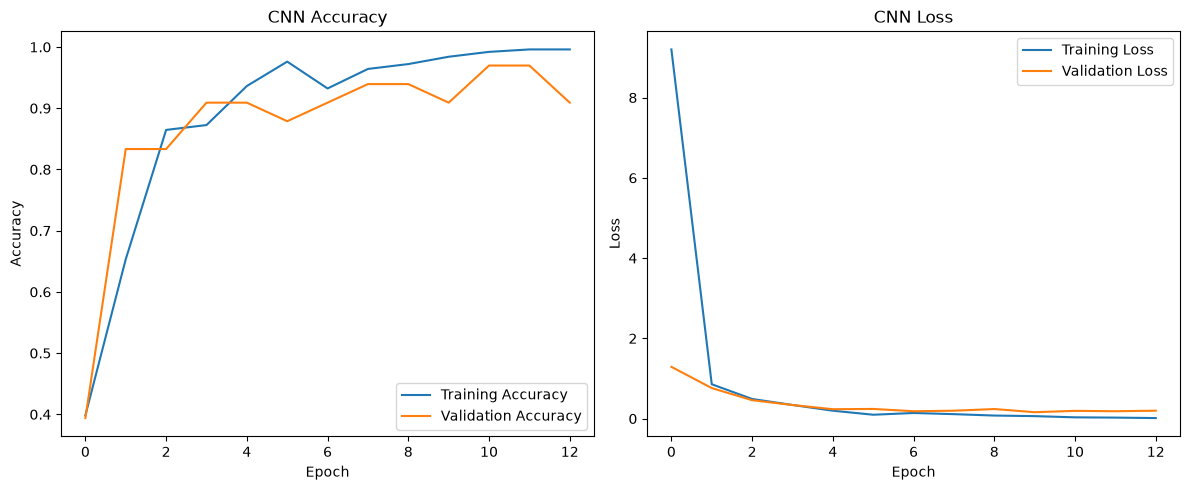

In [18]:
plt.figure(figsize=(12, 5))

# Accuracy Plot
plt.subplot(1, 2, 1)

plt.plot(cnn_history.history["accuracy"], label="Training Accuracy")

plt.plot(cnn_history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)

plt.plot(cnn_history.history["loss"], label="Training Loss")

plt.plot(cnn_history.history["val_loss"], label="Validation Loss")

plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()

plt.savefig("../images/training_history.png")

plt.show()

### Training Analysis

The CNN showed strong learning performance throughout training.

Training accuracy increased rapidly while validation accuracy remained high, indicating that the model successfully learned image features from the chest X-ray dataset.

The validation loss remained low compared with the baseline neural network, demonstrating improved generalization and prediction confidence on unseen images.

### Training Curve Analysis

The CNN demonstrated strong learning performance throughout training.

Training accuracy increased steadily and converged close to 100%, while validation accuracy stabilized above 90%.

Validation loss decreased rapidly during the first few epochs and remained low throughout training, indicating that the model was able to generalize effectively to unseen chest X-ray images.

Although a small amount of overfitting is visible toward the end of training, the gap between training and validation performance remains relatively small. Overall, the CNN achieved substantially better performance than the baseline dense neural network.